# Wealth-Weighted Exchange

The first new exchange mechanism of the project. Motivated by "the rich get richer" (the Matthew effect), the counterparty in each exchange is chosen in proportion to its wealth, while the winner is still decided by a fair coin flip so wealthier agents are not favoured as winners.

### Set Up
- $N$ agents with initial wealth $m$, so total wealth is $M = Nm$
- Choose agent $i$ uniformly at random
- Choose agent $j \neq i$ with probability proportional to its wealth:
 $$ p(j \mid i) = \frac{m_j}{\sum_{k \neq i} m_k} = \frac{m_j}{M - m_i} $$
- Pick the winner $b$ (and thus the loser $a$) with a fair coin flip
- Draw $\Delta m \sim U(0, m)$
- If $m_a \ge \Delta m$: $\ m_a \rightarrow m_a - \Delta m$ and $m_b \rightarrow m_b + \Delta m$

In [1]:
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
from wealth_dist.plotting import plot_simulation_results, plot_pareto_ccdf_grid
from wealth_dist.stats_analysis import pareto_tail_fits

np.random.seed()  # for reproducibility

In [2]:
### PARAMS -----------------------------------------------------------------------------------------------------------------------

N = 10000 #agents
m = 100 #wealth
sims = 100000

### CALCULATIONS -----------------------------------------------------------------------------------------------------------------------

prints = sims // 100 # only calculate entropy every 1% of simulations

M = N*m #Total Wealth

wealth = np.ones(N) * m
index = np.arange(N)
entropy = []

### PIPELINE -----------------------------------------------------------------------------------------------------------------------

for sim in range(sims):

    i = random.choice(N) 
    m_i = wealth[i]

    if m_i == M: 
        break

### SET UP PROB DISTRIBUTION
    
    probs = wealth / (M - m_i)
    probs[i] = 0 # agent i cannot trade with itself
    j = np.random.choice(index, p = probs)



    loser = np.random.choice([i,j])  #"Coin Flip"
    winner = j if loser == i else i
    dm = np.random.uniform(0, m) 

    if wealth[loser] >= dm:
        wealth[loser] += -dm
        wealth[winner] += dm

    ### ENTROPY CALCULATIONS EVERY 1%

    if sim % prints == 0:

        bin_edges = np.arange(0, wealth.max() + 1) # unit-width bins
        vec, _ = np.histogram(wealth, bins = bin_edges)
        vec = vec[vec != 0] #problems with log 0 and less computation
        Pb = vec/N
        entropy.append(-np.sum(Pb*np.log(Pb)))

        #Progress prints
        if sim % (prints * 10) == 0:
            print(f"{(sim/ sims) *100}% completed, max wealth:{100*(wealth.max() / M):.3f}%, entropy:{entropy[-1]:.3f}")

0.0% completed, max wealth:0.014%, entropy:0.002
10.0% completed, max wealth:0.056%, entropy:5.102
20.0% completed, max wealth:0.064%, entropy:5.522
30.0% completed, max wealth:0.071%, entropy:5.565
40.0% completed, max wealth:0.069%, entropy:5.571
50.0% completed, max wealth:0.078%, entropy:5.568
60.0% completed, max wealth:0.073%, entropy:5.572
70.0% completed, max wealth:0.085%, entropy:5.571
80.0% completed, max wealth:0.093%, entropy:5.571
90.0% completed, max wealth:0.091%, entropy:5.568


The histogram and entropy over time. The entropy levels off, so the run has reached a stationary state.

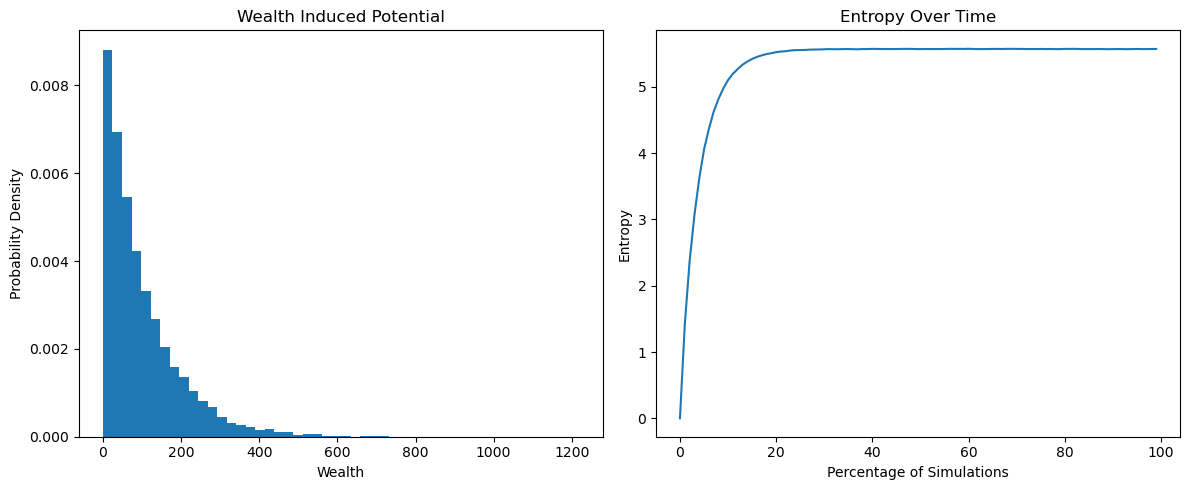

In [3]:
plot_simulation_results([wealth, entropy], bins=50, title="Wealth Induced Potential", figsize = (12,5))

Pareto fits to the top 10%, 5%, 2.5% and 1% of agents. The reported `alpha` is the exponent of the fitted CCDF, $P(W > w) \propto w^{-\alpha}$. The KS test is shown with its p-value.

In [4]:
fitting = pareto_tail_fits(wealth)


Top 10% tail
xmin = 230.43046799097164
n_tail = 1000
alpha = 3.2592394537457143
KS = 0.06277498137483606
p-value = 0.0007206852611013618

Top 5% tail
xmin = 292.68819536132844
n_tail = 500
alpha = 3.7878142193517164
KS = 0.07673366709387996
p-value = 0.005240958964506114

Top 2.5% tail
xmin = 364.9831026553248
n_tail = 250
alpha = 4.846566538539423
KS = 0.0980118683491506
p-value = 0.015274982732943984

Top 1% tail
xmin = 450.8052576866442
n_tail = 100
alpha = 6.199939484131585
KS = 0.057880475501178585
p-value = 0.871580383377634


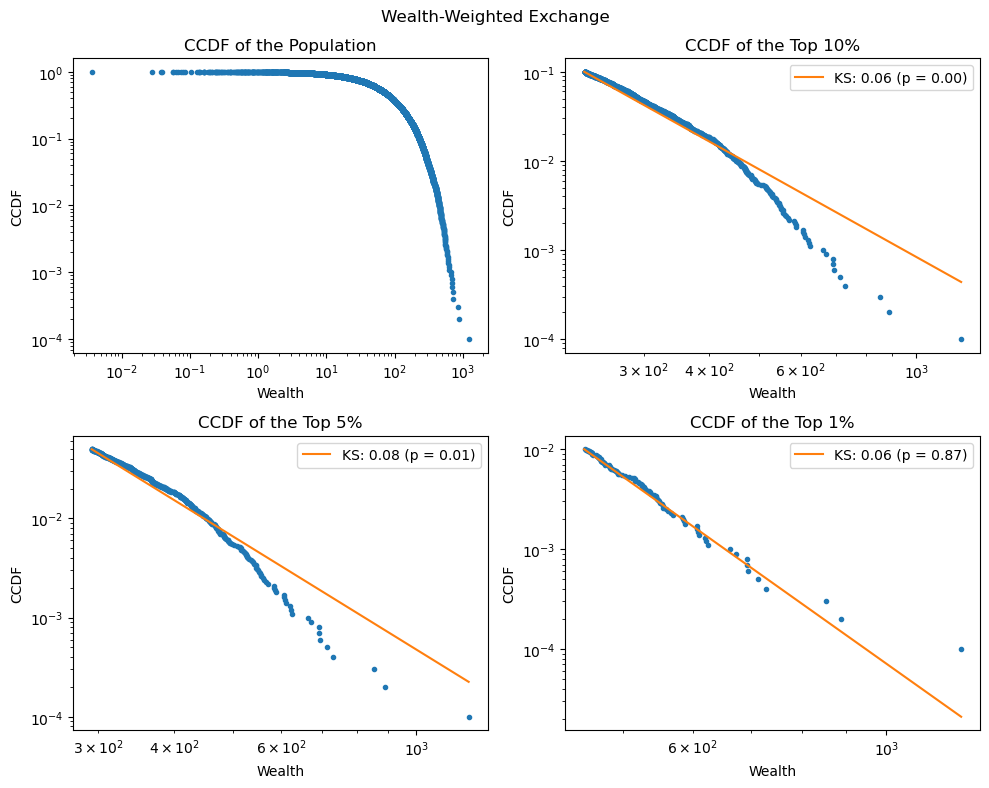

In [5]:
plot_pareto_ccdf_grid(wealth, fitting, title="Wealth-Weighted Exchange")

The tail is longer than in the DY model, but the fitted exponent increases steadily as the threshold moves further into the tail (from about 3 for the top 10% to about 6 for the top 1%). A true power law would give a stable exponent, so wealth-weighted selection alone is not enough to produce a Pareto tail. The high KS p-values for the smallest tails mostly reflect the small sample size (100–250 agents).